In [94]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score

In [95]:
df_clean = pd.read_csv('clean_cafe_sales.csv')

In [96]:
# Final untuk analisis
df_final = df_clean.copy()

In [97]:
print(f"Jumlah Data Final: {df_final.shape[0]} baris")

Jumlah Data Final: 9227 baris


In [98]:
df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9227 entries, 0 to 9226
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    9227 non-null   object 
 1   Item              9227 non-null   object 
 2   Quantity          9227 non-null   float64
 3   Price Per Unit    9227 non-null   float64
 4   Total Spent       9227 non-null   float64
 5   Payment Method    9227 non-null   object 
 6   Location          9227 non-null   object 
 7   Transaction Date  9227 non-null   object 
 8   Month             9227 non-null   object 
 9   Day_of_Week       9227 non-null   object 
 10  Year              9227 non-null   int64  
 11  Month_Year        9227 non-null   object 
dtypes: float64(3), int64(1), object(8)
memory usage: 865.2+ KB


In [99]:
# Cek apakah sudah benar" bersih
pd.DataFrame({
    "missing_values": df_final.isnull().sum(),
    "missing_values_percentage":  df_final.isnull().sum() / len(df_final) * 100,
    "duplicate_rows": df_final.duplicated().sum()
})

,missing_values,missing_values_percentage,duplicate_rows
Transaction ID,0,0.0,0
Item,0,0.0,0
Quantity,0,0.0,0
Price Per Unit,0,0.0,0
Total Spent,0,0.0,0
Payment Method,0,0.0,0
Location,0,0.0,0
Transaction Date,0,0.0,0
Month,0,0.0,0
Day_of_Week,0,0.0,0


In [100]:
# Pengecekan values dari masing" Category
print(df_final['Location'].unique())
print(df_final['Payment Method'].unique())
print(df_final['Item'].unique())

['Takeaway' 'In Store' 'Unknown']
['Credit Card' 'Cash' 'Unknown' 'Digital Wallet']
['Coffee' 'Cake' 'Cookie' 'Salad' 'Smoothie' 'Juice' 'Sandwich' 'Tea']


In [101]:
df_final["Item"].value_counts()

,count
Item,
Juice,1246
Coffee,1239
Sandwich,1186
Cake,1185
Cookie,1144
Smoothie,1138
Tea,1135
Salad,954


In [102]:
df_final.head(13)

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date,Month,Day_of_Week,Year,Month_Year
0,TXN_1961373,Coffee,2.0,2.0,4.0,Credit Card,Takeaway,2023-09-08,September,Friday,2023,2023-09
1,TXN_4977031,Cake,4.0,3.0,12.0,Cash,In Store,2023-05-16,May,Tuesday,2023,2023-05
2,TXN_4271903,Cookie,4.0,1.0,4.0,Credit Card,In Store,2023-07-19,July,Wednesday,2023,2023-07
3,TXN_7034554,Salad,2.0,5.0,10.0,Unknown,Unknown,2023-04-27,April,Thursday,2023,2023-04
4,TXN_3160411,Coffee,2.0,2.0,4.0,Digital Wallet,In Store,2023-06-11,June,Sunday,2023,2023-06
5,TXN_2602893,Smoothie,5.0,4.0,20.0,Credit Card,Unknown,2023-03-31,March,Friday,2023,2023-03
6,TXN_4433211,Juice,3.0,3.0,9.0,Unknown,Takeaway,2023-10-06,October,Friday,2023,2023-10
7,TXN_6699534,Sandwich,4.0,4.0,16.0,Cash,Unknown,2023-10-28,October,Saturday,2023,2023-10
8,TXN_4717867,Juice,5.0,3.0,15.0,Unknown,Takeaway,2023-07-28,July,Friday,2023,2023-07
9,TXN_2064365,Sandwich,5.0,4.0,20.0,Unknown,In Store,2023-12-31,December,Sunday,2023,2023-12


In [103]:
# Bentuk Deskriptif Statistik dari df_final
df_final.describe().T

,count,mean,std,min,25%,50%,75%,max
Quantity,9227.0,2.966728,1.400225,1.0,2.0,3.0,4.0,5.0
Price Per Unit,9227.0,2.891893,1.249362,1.0,2.0,3.0,4.0,5.0
Total Spent,9227.0,8.474369,5.441998,1.0,4.0,7.5,12.0,20.0
Year,9227.0,2023.000000,0.000000,2023.0,2023.0,2023.0,2023.0,2023.0


In [104]:
df_final.to_csv('clean_cafe_sales.csv', index=False)

In [105]:
df_final['Location'].value_counts()

,count
Location,
Unknown,3665
Takeaway,2791
In Store,2771


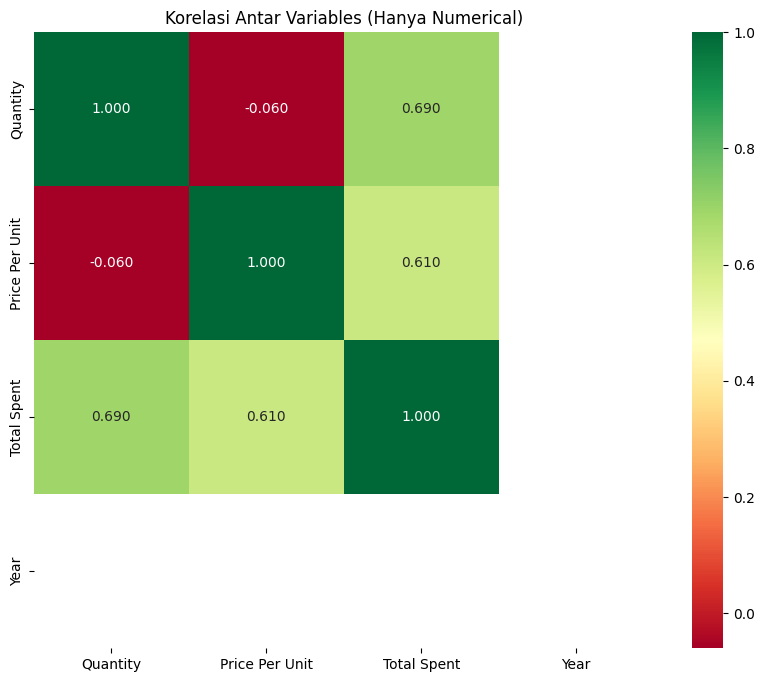

In [106]:
# Matriks Korelasi: Melihat faktor apa yang paling memengaruhi sales
plt.figure(figsize=(10, 8))
correlation_matrix = df_final.corr(numeric_only=True)
sns.heatmap(correlation_matrix, annot=True, cmap='RdYlGn', fmt=".3f")
plt.title('Korelasi Antar Variables (Hanya Numerical)')
plt.show()

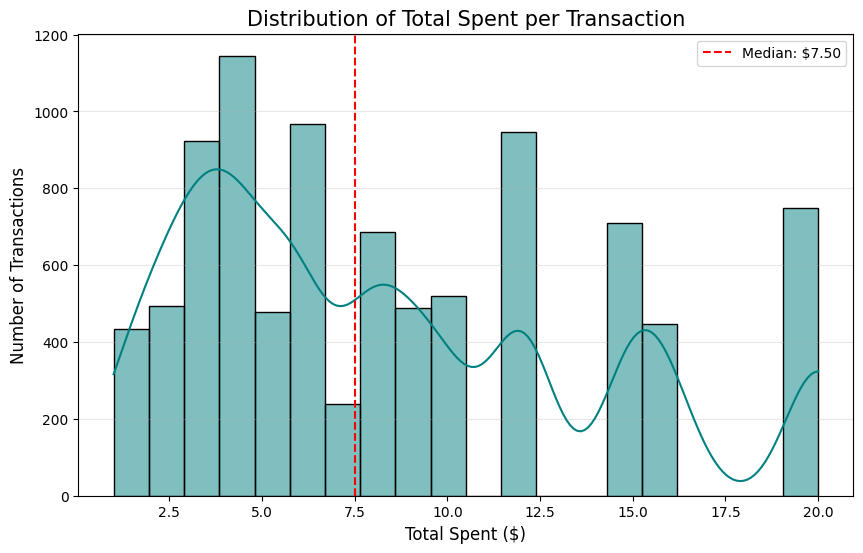

In [107]:
# Distribution dari Total Spent
plt.figure(figsize=(10, 6))
sns.histplot(df_final['Total Spent'], bins=20, kde=True, color='teal')

# Adding a vertical line for the Median to show the "tail"
plt.axvline(df_final['Total Spent'].median(), color='red', linestyle='--',
            label=f'Median: ${df_final["Total Spent"].median():.2f}')

plt.title('Distribution of Total Spent per Transaction', fontsize=15)
plt.xlabel('Total Spent ($)', fontsize=12)
plt.ylabel('Number of Transactions', fontsize=12)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

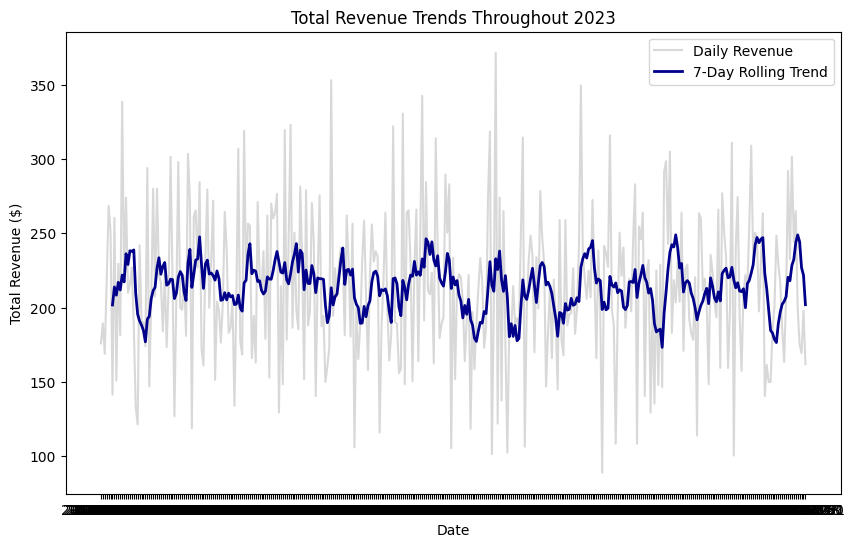

In [108]:
# Aggregate total sales dengan date
daily_sales = df_final.groupby('Transaction Date')['Total Spent'].sum().reset_index()

# Average berjalan untuk memperhalus garis (menjadi smooth)
daily_sales['Rolling_Mean'] = daily_sales['Total Spent'].rolling(window=7).mean()

plt.figure(figsize=(10, 6))

# Plotting daily sales mentah
sns.lineplot(x='Transaction Date', y='Total Spent', data=daily_sales, alpha=0.3, label='Daily Revenue', color='gray')

# Plotting average berjalan (The "Trend" line)
sns.lineplot(x='Transaction Date', y='Rolling_Mean', data=daily_sales, color='darkblue', linewidth=2, label='7-Day Rolling Trend')

plt.title('Total Revenue Trends Throughout 2023')
plt.xlabel('Date')
plt.ylabel('Total Revenue ($)')
plt.legend()
plt.show()

/tmp/ipykernel_773/2830955341.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=item_revenue.index, y=item_revenue.values, palette='viridis')


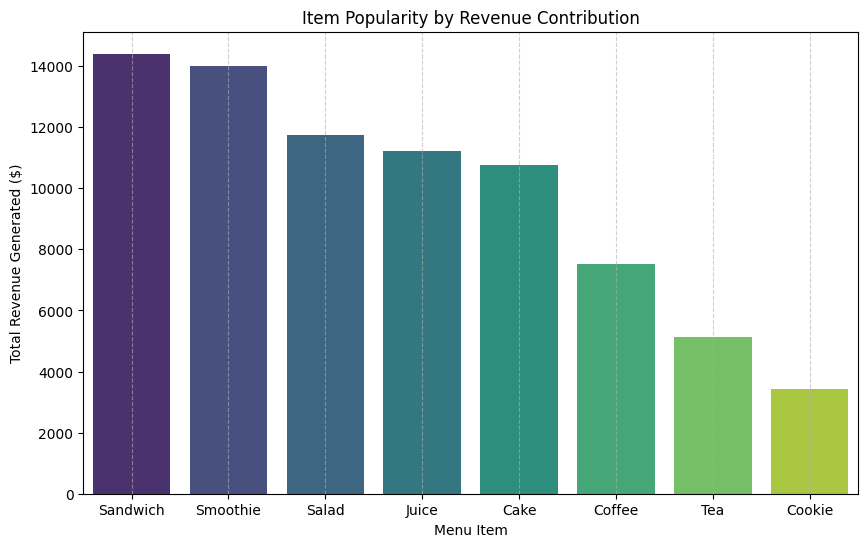

In [109]:
# Item's Popularity by Revenue
item_revenue = df_final.groupby('Item')['Total Spent'].sum().sort_values(ascending=False)
plt.figure(figsize=(10, 6))
sns.barplot(x=item_revenue.index, y=item_revenue.values, palette='viridis')
plt.title('Item Popularity by Revenue Contribution')
plt.xlabel('Menu Item')
plt.ylabel('Total Revenue Generated ($)')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.show()

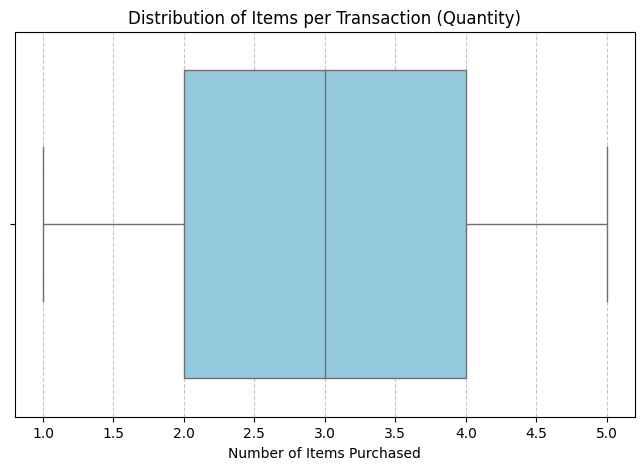

In [110]:
# Quantity Analysis
plt.figure(figsize=(8, 5))

# Horizontal Boxplot
sns.boxplot(x=df_final['Quantity'], color='skyblue', fliersize=5)

plt.title('Distribution of Items per Transaction (Quantity)')
plt.xlabel('Number of Items Purchased')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

/tmp/ipykernel_773/3944394979.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Location', y='Total Spent', data=df_final, estimator=sum, palette='viridis')


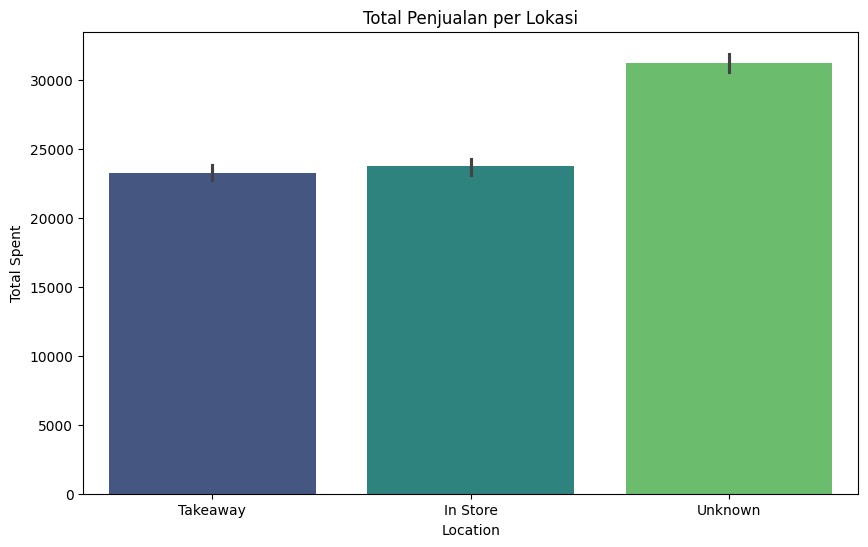

In [111]:
# Apakah lokasi tertentu belanja lebih banyak?
plt.figure(figsize=(10, 6))
sns.barplot(x='Location', y='Total Spent', data=df_final, estimator=sum, palette='viridis')
plt.title('Total Penjualan per Lokasi')
plt.xticks()
plt.show()

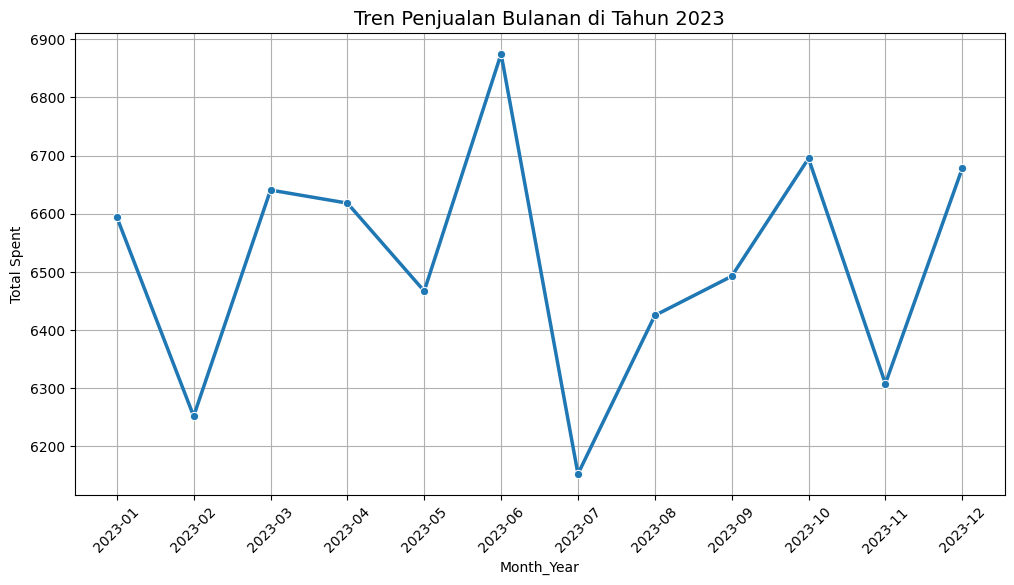

In [112]:
# Tren Bulanan (lebih ke pertumbuhan bisnis)
plt.figure(figsize=(12, 6))
monthly_sales = df_final.groupby('Month_Year')['Total Spent'].sum().reset_index()
monthly_sales['Month_Year'] = monthly_sales['Month_Year'].astype(str) # Ubah ke string buat plotting

sns.lineplot(data=monthly_sales, x='Month_Year', y='Total Spent', marker='o', linewidth=2.5)
plt.title('Tren Penjualan Bulanan di Tahun 2023', fontsize=14)
plt.xticks(rotation=45)
plt.grid(True, linestyle='-', alpha=1)
plt.show()

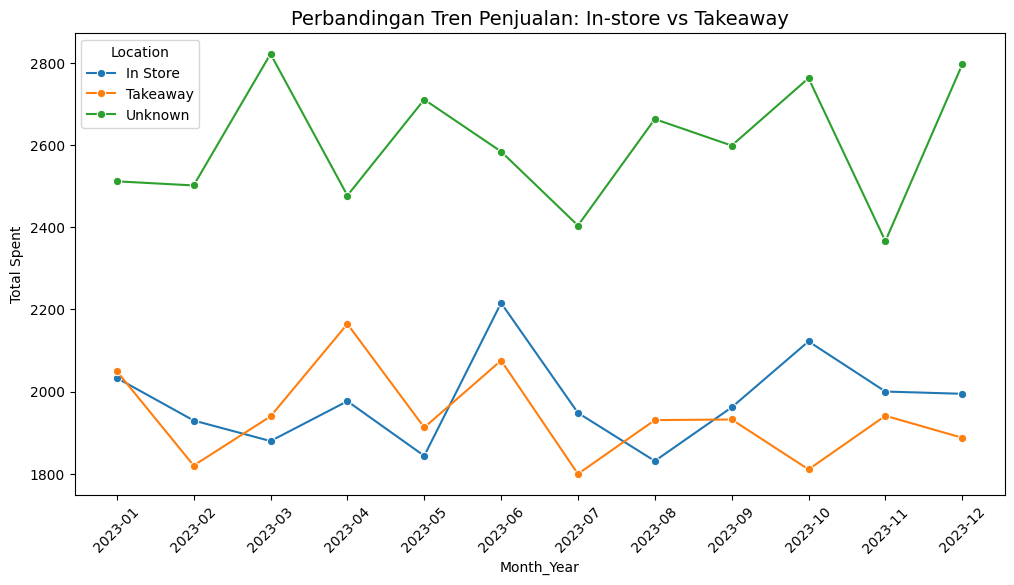

In [113]:
# Perbandingan Tren: In-store vs Takeaway (Mencari Hubungan/Relationship)
plt.figure(figsize=(12, 6))
# Group berdasarkan tanggal & lokasi
trend_compare = df_final.groupby(['Month_Year', 'Location'])['Total Spent'].sum().reset_index()
trend_compare['Month_Year'] = trend_compare['Month_Year'].astype(str)

sns.lineplot(data=trend_compare, x='Month_Year', y='Total Spent', hue='Location', marker='o')
plt.title('Perbandingan Tren Penjualan: In-store vs Takeaway', fontsize=14)
plt.xticks(rotation=45)
plt.show()

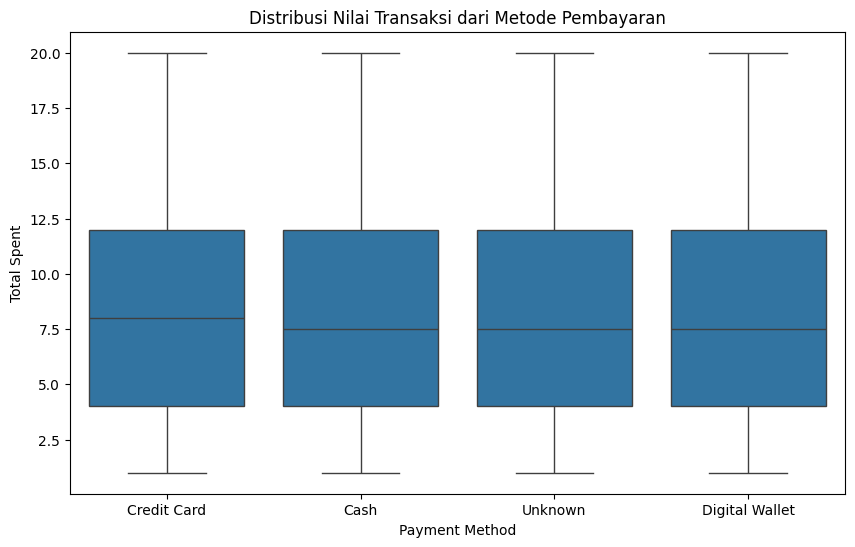

In [114]:
# Hubungan antara Payment Method dan Total Spent (Boxplot)
plt.figure(figsize=(10, 6))
sns.boxplot(x='Payment Method', y='Total Spent', data=df_final)
plt.title('Distribusi Nilai Transaksi dari Metode Pembayaran')
plt.show()

/tmp/ipykernel_773/344190463.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Day_of_Week', data=df_final, order=order, palette='viridis')


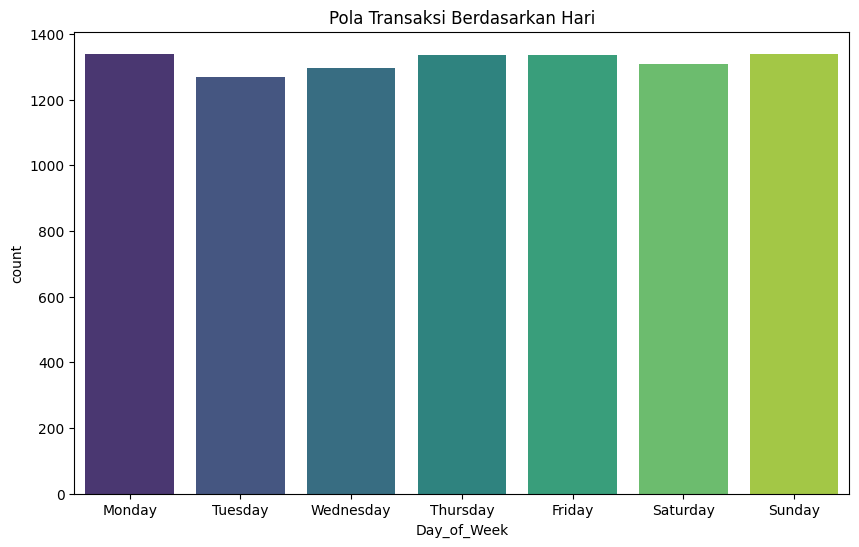

In [115]:
# Patterns
# Hari apa yang paling ramai (untuk strategi restocking / penentuan jumlah karyawan)
plt.figure(figsize=(10, 6))
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
sns.countplot(x='Day_of_Week', data=df_final, order=order, palette='viridis')
plt.title('Pola Transaksi Berdasarkan Hari')
plt.show()

In [116]:
# HYPOTHESIS TESTING
from scipy import stats

# Define our groups for A/B testing using the 'Location' column
group_a = df_final[df_final['Location'] == 'In Store']['Total Spent']
group_b = df_final[df_final['Location'] == 'Takeaway']['Total Spent']

# Ignore 'Unknown' locations for this specific A/B test comparison

print(f"Mean Total Spent for In Store: ${group_a.mean():.2f}")
print(f"Mean Total Spent for Takeaway: ${group_b.mean():.2f}")

# Hypotheses:
# H0: There is no significant difference in the mean Total Spent between 'In Store' and 'Takeaway' locations.
# H1: There is a significant difference in the mean Total Spent between 'In Store' and 'Takeaway' locations.

# Perform an independent t-test
# The 'equal_var=False' -> used when assuming that the population variances are not equal.
t_stat, p_value = stats.ttest_ind(group_a, group_b, equal_var=False)

print(f"\nIndependent t-test results:")
print(f"T-statistic: {t_stat:.2f}")
print(f"P-value: {p_value:.4f}")

# Interpret the p-value
alpha = 0.05

if p_value < alpha:
    print(f"\nConclusion: Since the p-value ({p_value:.4f}) is less than the significance level ({alpha}), we reject the null hypothesis.")
    print(f"There is a statistically significant difference in the mean Total Spent between 'In Store' and 'Takeaway' locations.")
else:
    print(f"\nConclusion: Since the p-value ({p_value:.4f}) is greater than the significance level ({alpha}), we fail to reject the null hypothesis.")
    print(f"There is no statistically significant difference in the mean Total Spent between 'In Store' and 'Takeaway' locations.")


Mean Total Spent for In Store: $8.57
Mean Total Spent for Takeaway: $8.33

Independent t-test results:
T-statistic: 1.58
P-value: 0.1137

Conclusion: Since the p-value (0.1137) is greater than the significance level (0.05), we fail to reject the null hypothesis.
There is no statistically significant difference in the mean Total Spent between 'In Store' and 'Takeaway' locations.


In [117]:
# PREDICTIVE ANALYSIS
# Agregasi Total Spent per Hari (Bukan per transaksi), filter hanya yang memiliki tanggal untuk modeling
df_model = df_final.copy()
daily_data = df_model.groupby('Transaction Date')['Total Spent'].sum().reset_index()
daily_data = daily_data.sort_values('Transaction Date')

In [118]:
# Ambil kolom Total Spent sebagai array
data = daily_data['Total Spent'].values.reshape(-1, 1)

In [119]:
import numpy as np
# Mengonversi data menjadi sequences untuk input model RandomForestRegressor (Time-Step: 14 hari)
# Metode Sliding Window
def create_sequences(dataset, window_size):
    X, y = [], []
    for i in range(len(dataset) - window_size):
        # Fitur -> Data 14 hari terakhir
        X.append(dataset[i : i + window_size, 0])

        # Target -> Penjualan di hari ke-15
        y.append(dataset[i + window_size, 0])
    return np.array(X), np.array(y)

WINDOW_SIZE = 14
X, y = create_sequences(data, WINDOW_SIZE)

In [120]:
# Split data -> 80% Train, 20% Test
train_size = int(len(X) * 0.8)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

In [121]:
from sklearn.ensemble import RandomForestRegressor

#  Menyiapkan data untuk Random Forest (Flattening)
# LSTM butuh 3D (samples, time_steps, features), RF butuh 2D (samples, time_steps*features)
X_train_rf = X_train.reshape(X_train.shape[0], -1)
X_test_rf = X_test.reshape(X_test.shape[0], -1)

# Inisialisasi dan Training Random Forest
rf_model = RandomForestRegressor(n_estimators=100,
                                 random_state=42,
                                 min_samples_leaf=1,
                                 min_samples_split=2,
                                 max_depth=None)
rf_model.fit(X_train_rf, y_train)

# Prediksi pada Test Set
y_pred_rf = rf_model.predict(X_test_rf)
y_pred = y_pred_rf.reshape(-1, 1) # Menyesuaikan variabel agar kompatibel dengan sisa code

# Evaluasi
# Since data was not scaled, y_test and y_pred are already in original scale.
# No inverse transform is needed.
y_test_inv = y_test.reshape(-1, 1)
y_pred_inv = y_pred

mae = mean_absolute_error(y_test_inv, y_pred_inv)
mape = mean_absolute_percentage_error(y_test_inv, y_pred_inv)
r2 = r2_score(y_test_inv, y_pred_inv)

print(f"Hasil Random Forest:")
print(f"MAE: {mae:.2f}")
print(f"MAPE: {mape:.2f}")
print(f"R2 Score: {r2:.2f}")

# Forecasting 30 Hari (Recursive)
# Use 'data' directly as the model was trained on unscaled data.
last_window = data[-WINDOW_SIZE:].flatten().reshape(1, -1)
future_preds_rf = []

for _ in range(30):
    pred = rf_model.predict(last_window)[0]
    future_preds_rf.append(pred)
    # Update window: buang index pertama, masukkan prediksi terbaru ke index terakhir
    last_window = np.append(last_window[0, 1:], pred).reshape(1, -1)

# Predictions are already in the original scale, no inverse transform needed.
future_preds = np.array(future_preds_rf).reshape(-1, 1)
total_forecast = np.sum(future_preds)

print(f"\nPrediksi Total Pendapatan Bulan Depan: ${total_forecast:.2f}")

Hasil Random Forest:
MAE: 34.62
MAPE: 0.18
R2 Score: 0.09

Prediksi Total Pendapatan Bulan Depan: $6371.79


In [122]:
from sklearn.model_selection import GridSearchCV

# Hyperparameter Tuning for RandomForestRegressor
# Define the parameter grid to search
param_grid = {
    'n_estimators': [100, 200],  # Number of trees in the forest
    'max_depth': [None, 10, 20, 30], # Maximum depth of the tree
    'min_samples_split': [1, 2, 5, 10], # Minimum number of samples required to split an internal node
    'min_samples_leaf': [1, 2, 3, 4]    # Minimum number of samples required to be at a leaf node
}

# Initialize GridSearchCV
# 'cv' is the number of folds for cross-validation
# 'scoring' is the metric to optimize (e.g., 'neg_mean_absolute_error' for MAE)
grid_search = GridSearchCV(estimator=RandomForestRegressor(random_state=42),
                           param_grid=param_grid,
                           cv=3, # Using 3-fold cross-validation
                           scoring='neg_mean_absolute_error', # Optimize for MAE
                           n_jobs=-1, # Use all available cores
                           verbose=2)

# Fit GridSearchCV to the training data
print("Starting GridSearchCV...")
grid_search.fit(X_train_rf, y_train)
print("GridSearchCV completed.")

# Get the best parameters and best score
best_params = grid_search.best_params_
best_score = -grid_search.best_score_ # Convert negative MAE to positive MAE

print(f"\nBest Parameters found: {best_params}")
print(f"Best MAE found (from CV): {best_score:.2f}")

# Train a new model with the best parameters
rf_model_tuned = RandomForestRegressor(**best_params, random_state=42)
rf_model_tuned.fit(X_train_rf, y_train)

# Make predictions on the Test Set
y_pred_tuned = rf_model_tuned.predict(X_test_rf)
y_pred_tuned_inv = y_pred_tuned.reshape(-1, 1)

# Evaluate the tuned model on the Test Set
mae_tuned = mean_absolute_error(y_test_inv, y_pred_tuned_inv)
mape_tuned = mean_absolute_percentage_error(y_test_inv, y_pred_tuned_inv)
r2_tuned = r2_score(y_test_inv, y_pred_tuned_inv)

print(f"\nResults with Tuned Random Forest Model (on Test Set):")
print(f"MAE: {mae_tuned:.2f}")
print(f"MAPE: {mape_tuned:.2f}")
print(f"R2 Score: {r2_tuned:.2f}")


Starting GridSearchCV...
Fitting 3 folds for each of 128 candidates, totalling 384 fits


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
96 fits failed out of a total of 384.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
96 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/usr/local/lib/python3.12/dist-packages/sklearn/base.py", line 1382, in wrapper
    estimator._validate_params()
  File "/usr/local/lib/python3.12/dist-packages/sklearn/base.py", line 436, in _validate_params
    validate_parameter_constraints(
  File "/usr/local/lib/python3.12/dist-packages/sklearn/utils/

GridSearchCV completed.

Best Parameters found: {'max_depth': None, 'min_samples_leaf': 3, 'min_samples_split': 10, 'n_estimators': 100}
Best MAE found (from CV): 41.86

Results with Tuned Random Forest Model (on Test Set):
MAE: 35.33
MAPE: 0.18
R2 Score: 0.07


#### Forecasting with Tuned Model

Let's use the tuned model to forecast future sales for 30 days.

In [123]:
# Forecasting 30 Hari (Recursive) with the tuned model
last_window_tuned = data[-WINDOW_SIZE:].flatten().reshape(1, -1)
future_preds_tuned = []

for _ in range(30):
    pred_tuned = rf_model_tuned.predict(last_window_tuned)[0]
    future_preds_tuned.append(pred_tuned)
    # Update window: buang index pertama, masukkan prediksi terbaru ke index terakhir
    last_window_tuned = np.append(last_window_tuned[0, 1:], pred_tuned).reshape(1, -1)

# Predictions are already in the original scale, no inverse transform needed.
future_preds_tuned_array = np.array(future_preds_tuned).reshape(-1, 1)
total_forecast_tuned = np.sum(future_preds_tuned_array)

print(f"Prediksi Total Pendapatan Bulan Depan (Tuned Model): ${total_forecast_tuned:.2f}")


Prediksi Total Pendapatan Bulan Depan (Tuned Model): $6361.46


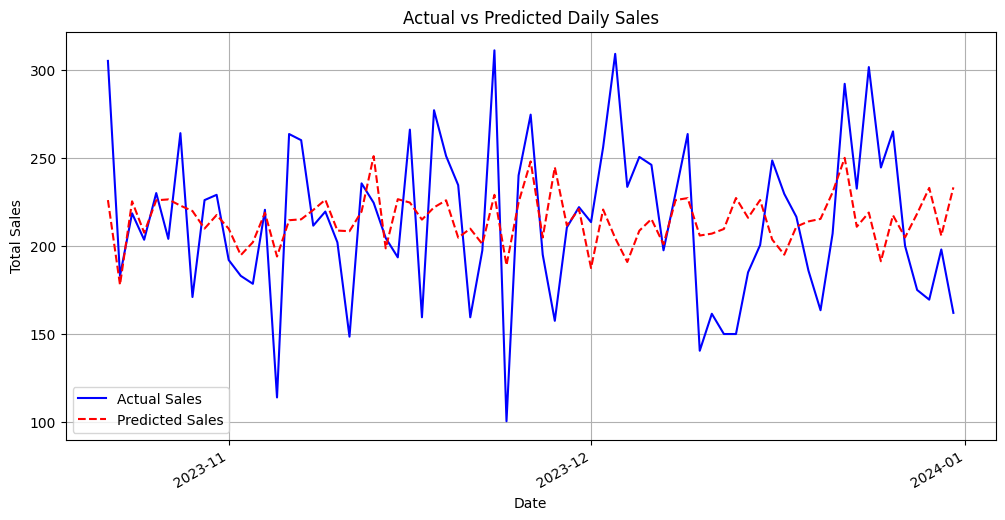

In [124]:
# Get the actual dates corresponding to the test set
test_dates = daily_data['Transaction Date'][train_size + WINDOW_SIZE:].reset_index(drop=True)

# DF untuk plotting
plot_df = pd.DataFrame({
    'Date': test_dates,
    'Actual Sales': y_test_inv.flatten(),
    'Predicted Sales': y_pred_inv.flatten()
})

# Convert 'Date' column to datetime objects for better plotting
plot_df['Date'] = pd.to_datetime(plot_df['Date'])

# Plot actual vs predicted values
plt.figure(figsize=(12, 6))
sns.lineplot(x='Date', y='Actual Sales', data=plot_df, label='Actual Sales', color='blue')
sns.lineplot(x='Date', y='Predicted Sales', data=plot_df, label='Predicted Sales', color='red', linestyle='--')

plt.title('Actual vs Predicted Daily Sales')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.legend()
plt.grid(True)

# Date formatting
import matplotlib.dates as mdates

# Set major ticks to show start of each month
plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=1))

# Format the dates as 'YYYY-MM'
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))

# Rotate date labels for better readability
plt.gcf().autofmt_xdate()

plt.show()

In [125]:
# Kontribusi historis setiap produk terhadap total pendapatan
product_contribution = df_final.groupby('Item')['Total Spent'].sum().reset_index()
total_historical_revenue = product_contribution['Total Spent'].sum()

In [126]:
# Persentase kontribusi
product_contribution['Contribution_Pct'] = (product_contribution['Total Spent'] / total_historical_revenue)

In [127]:
# Prediksi Pendapatan per Produk untuk Bulan Depan
product_contribution['Forecasted_Revenue_Next_Month'] = product_contribution['Contribution_Pct'] * total_forecast

In [128]:
# Menentukan Status Restocking
# Karena ada 8 jenis item (Sandwich, Smoothie, Salad, Juice, Cake, Coffee, Tea, Cookie)
# Maka dari itu: 100% / 8 = 12.5% (untuk pembagian persentase kontribusi)
# > 15% kontribusi = High Priority (Restock More)
# 5-15% kontribusi = Medium (Maintain)
# < 5% kontribusi = Low Priority (Reduce / Watch)

def get_restock_status(pct):
    if pct > 0.15:
        return 'High Priority (Restock More)'
    elif pct > 0.05:
        return 'Medium (Maintain)'
    else:
        return 'Low Priority (Reduce Stock)'

product_contribution['Restock_Action'] = product_contribution['Contribution_Pct'].apply(get_restock_status)


# Menampilkan persentase kontribusi masing" item
product_contribution = product_contribution.sort_values(by='Contribution_Pct', ascending=False)

for i in product_contribution['Item']:
    val = product_contribution.loc[product_contribution['Item'] == i, 'Contribution_Pct'].values[0]
    print(f"{i}: {val * 100:.2f}%")

Sandwich: 18.42%
Smoothie: 17.91%
Salad: 15.01%
Juice: 14.33%
Cake: 13.77%
Coffee: 9.61%
Tea: 6.57%
Cookie: 4.37%


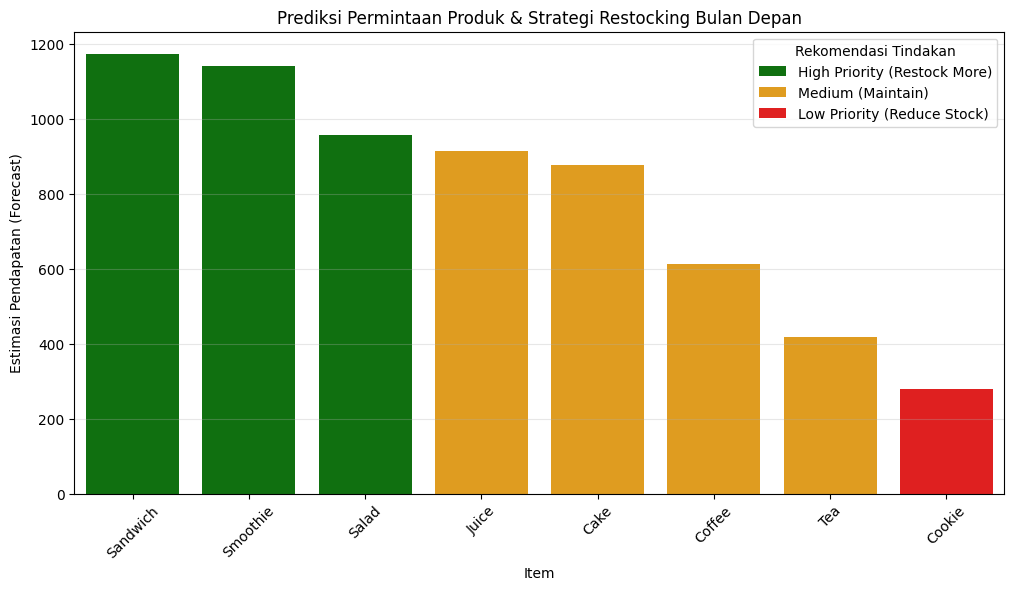

In [129]:
# Urutkan berdasarkan profit tertinggi
plt.figure(figsize=(12, 6))
colors = {'High Priority (Restock More)': 'green', 'Medium (Maintain)': 'orange', 'Low Priority (Reduce Stock)': 'red'}

# Menyusun urutan berdasarkan Prioritas
priority_order = ['High Priority (Restock More)', 'Medium (Maintain)', 'Low Priority (Reduce Stock)']
product_contribution['Restock_Action'] = pd.Categorical(product_contribution['Restock_Action'],
                                                        categories=priority_order, ordered=True)

# Urutkan DataFrame berdasarkan Restock_Action dan setelah itu, berdasarkan Forecasted_Revenue_Next_Month
product_contribution_sorted = product_contribution.sort_values(by=['Restock_Action', 'Forecasted_Revenue_Next_Month'],
                                                               ascending=[True, False])

sns.barplot(data=product_contribution_sorted, x='Item', y='Forecasted_Revenue_Next_Month',
            hue='Restock_Action', palette=colors, dodge=False)

plt.title('Prediksi Permintaan Produk & Strategi Restocking Bulan Depan')
plt.ylabel('Estimasi Pendapatan (Forecast)')
plt.xticks(rotation=45)
plt.legend(title='Rekomendasi Tindakan')
plt.grid(axis='y', alpha=0.3)
plt.show()

In [130]:
# Persentase Perubahan (Sebelum Tuning)
current_total = daily_data['Total Spent'].tail(30).sum()
growth_rate_beforeTuning = ((total_forecast - current_total) / current_total) * 100

In [131]:
print(f"Estimasi Pendapatan Historis (30 Hari Terakhir): ${current_total:.2f}")
print(f"Estimasi Perubahan Sebelum Tuning: {growth_rate_beforeTuning:.2f}%")

if growth_rate_beforeTuning < 0:
    status = "PENURUNAN"

else:
    status = "PENINGKATAN"

print(f"Status {status}")

Estimasi Pendapatan Historis (30 Hari Terakhir): $6464.50
Estimasi Perubahan Sebelum Tuning: -1.43%
Status PENURUNAN


In [132]:
# Persentase Perubahan (Setelah Tuning)
current_total = daily_data['Total Spent'].tail(30).sum()
growth_rate_afterTuning = ((total_forecast_tuned - current_total) / current_total) * 100

In [133]:
print(f"Estimasi Pendapatan Historis (30 Hari Terakhir): ${current_total:.2f}")
print(f"Estimasi Perubahan Setelah Tuning: {growth_rate_afterTuning:.2f}%")

if growth_rate_afterTuning < 0:
    status = "PENURUNAN"

else:
    status = "PENINGKATAN"

print(f"Status {status}")

Estimasi Pendapatan Historis (30 Hari Terakhir): $6464.50
Estimasi Perubahan Setelah Tuning: -1.59%
Status PENURUNAN
